# Figure 2: $F_1$ per cross-validation strategy

In [20]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.offsetbox import TextArea, HPacker, AnnotationBbox
import seaborn as sns

if 'google.colab' in str(get_ipython()): # running in colab
    !git clone --config lfs.fetchinclude="*"  https://github.com/sinc-lab/xvalRNAfolding.git
    !pip install -q scikit-posthocs
    DATA_PATH = './xvalRNAfolding/'
else:
    DATA_PATH = '../'
sys.path.insert(0, DATA_PATH + "src")
from summaries import load_summary, read_split, sim_auc

try:
    import scikit_posthocs as sp # critical difference diagrams
except ImportError:
    sp = None

DATASETS = ["archiveII", "bpRNA"]
for dataset in DATASETS:
    os.makedirs(f"{DATA_PATH}figures/{dataset}", exist_ok=True)

def save(dataset, partition_name):
    plt.savefig(f"{DATA_PATH}figures/{dataset}/Fig_F1_{partition_name}.pdf", bbox_inches='tight', dpi=300)
    plt.show()

In [21]:
# style globals: one color/marker per method, trained (blue) then classical (red)
METHODS = ["MxFold2", "REDfold", "UFold", "sincFold", "RiNALMo",
           "RNAfold", "RNAstructure", "LinearFoldV", "LinearPartitionV", "ProbKnot", "IPKnot"]
LABELS = {"MxFold2": "MXFold2"}
marker_colors = ["#6A6AFA", "#6262F8", "#2929FB", "#2929FF", "#0000FF",
                 "#FF746C", "#FC5141", "#FF2727", "#ED2100", "#FD0A0A", "#D20E00"]
mmarkers = ['o', 's', 'D', 'P', '*', '^', 'v', 'X', 'd', '<', '>']
marker_sizes = 0.1 * np.array([35, 30, 30, 45, 45, 50, 50, 50, 50, 50, 50]) # adjusted for smaller figures
STYLE = {m: dict(color=c, marker=mk, size=s) for m, c, mk, s in zip(METHODS, marker_colors, mmarkers, marker_sizes)}

strip_colors = sns.color_palette("tab10")
nshift = 8
strip_colors = strip_colors[nshift:] + strip_colors[:nshift]

font_size = 6 # max 7

plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['xtick.major.width'] = 0.5
plt.rcParams['ytick.major.width'] = 0.5
plt.rcParams['xtick.minor.width'] = 0.4
plt.rcParams['ytick.minor.width'] = 0.4
plt.rcParams['xtick.major.size'] = 2.5
plt.rcParams['ytick.major.size'] = 2.5

In [22]:
def fig_width(fig_size):
    # Oxford Bioinformatics: single column ~3.22 in, double column ~6.75 in
    return {"1col": 3.22, "2col": 6.75, "2in2col": 6.75/2, "3in2col": 6.75/3,
            "2x3in2col": 6.75/3*2 * 1.1}[fig_size]


def partition_sizes(split, key):
    """Test and train (train + valid) sizes per fold."""
    test = split[split["partition"] == "test"].groupby(key).size()
    train = split[split["partition"].isin(["train", "valid"])].groupby(key).size()
    return test, train


def size_bars(ax, order, test, train, small_h=0.05, train_dy=0.02, only_test=False):
    """Gray bars with the test proportion of each fold, labelled with test (ts) and train (tr) sizes
    (only the test size when every fold shares the same training set)."""
    tt = pd.DataFrame({"x": [str(k) for k in order], "partition": [test[k] / (test[k] + train[k]) for k in order]})
    sns.barplot(data=tt, x="x", y="partition", order=list(tt["x"]), edgecolor="w", facecolor="lightgrey",
                linewidth=2, alpha=0.6, err_kws={"color": "none", "linewidth": 0}, zorder=1, ax=ax)
    for bar, k in zip(ax.patches, order):
        x, w, h = bar.get_x(), bar.get_width(), bar.get_height()
        ax.plot([x, x + w], [h, h], color="black", linewidth=1, zorder=2)
        txt = dict(fontsize=font_size * 0.8)
        if only_test:
            ax.add_artist(AnnotationBbox(TextArea(f"{test[k]}", textprops=dict(color="darkred", **txt)),
                                         (x + w / 2, h + 0.005), xycoords="data", box_alignment=(0.5, 0), frameon=False))
        elif h < small_h:
            packed = HPacker(children=[TextArea(f"{test[k]}", textprops=dict(color="darkred", **txt)),
                                       TextArea(" | ", textprops=dict(color="black", **txt)),
                                       TextArea(f"{train[k]}", textprops=dict(color="black", **txt))],
                             align="center", pad=0, sep=0)
            ax.add_artist(AnnotationBbox(packed, (x + w, h + 0.005), xycoords="data", box_alignment=(1, 0), frameon=False))
        else:
            ax.add_artist(AnnotationBbox(TextArea(f"ts {test[k]}", textprops=dict(color="darkred", **txt)),
                                         (x + w, h + 0.005), xycoords="data", box_alignment=(1, 0), frameon=False))
            ax.add_artist(AnnotationBbox(TextArea(f"tr {train[k]}", textprops=dict(color="black", **txt)),
                                         (x + w, h - train_dy), xycoords="data", box_alignment=(1, 1), frameon=False))


def strip_folds(summary, split, x="fold", order=None, fig_size="2in2col", fig_height=2.0,
                strip_alpha=0.2, include_legend=False, n_train=None, rotate_xticks=False):
    """One strip of per-sequence F1 per fold (all methods dodged, colored by fold),
    the median F1 of each method as a marker, and the test proportion as a gray bar.
    n_train: training set size shared by all folds (when the split only lists test folds)."""
    key = "fold_name" if x == "family" else "fold_number"
    order = order if order is not None else sorted(summary[x].unique())
    methods = [m for m in METHODS if m in set(summary["method"])]

    fig, ax = plt.subplots(figsize=(fig_width(fig_size), fig_height), dpi=150)
    plt.rcParams.update({'font.size': font_size})

    sns.stripplot(data=summary, x=x, y="f1", hue="method", hue_order=methods, order=order,
                  dodge=True, jitter=0.25, alpha=0.15, size=2, zorder=1, legend=False, ax=ax)
    # recolor strips so all points from the same fold share the same color
    for coll in ax.collections:
        offsets = coll.get_offsets()
        if offsets is None or len(offsets) == 0:
            continue
        fold_idx = np.mod(np.rint(np.asarray(offsets)[:, 0]).astype(int), len(strip_colors))
        colors = [strip_colors[i] for i in fold_idx]
        coll.set_facecolors(colors)
        coll.set_edgecolors(colors)
        coll.set_alpha(strip_alpha)

    for i, method in enumerate(methods):
        medians = summary[summary["method"] == method].groupby(x)["f1"].median().reindex(order)
        offset = (i - (len(methods) - 1) / 2) * 0.08
        st = STYLE[method]
        ax.scatter(np.arange(len(order)) + offset, medians.values, color=st["color"], marker=st["marker"],
                   s=st["size"] * 4, edgecolor="black", linewidth=0.5, zorder=3, label=LABELS.get(method, method))

    test, train = partition_sizes(split, key)
    if n_train is not None:
        train = pd.Series(n_train, index=test.index)
    size_bars(ax, order, test, train, only_test=n_train is not None)
    if x == "fold":
        ax.set_xticks(range(len(order)), [f"fold {int(v) + 1}" for v in order])
    if rotate_xticks:
        ax.tick_params(axis="x", rotation=90)

    if include_legend:
        ax.legend(title="Methods", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=font_size)
    elif ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.tick_params(labelsize=font_size)
    ax.set_xlabel("")
    ax.set_ylabel("$F_1$ score", fontsize=font_size)
    plt.tight_layout()
    ax.set_ylim(0, 1)
    return fig, ax


def line_folds(summary, split, x, order, sizes_fold=None, train_dy=0.009, linewidth=0.5):
    """Mean F1 (and 95% CI) of each method per fold as lines, over the test proportion bars."""
    methods = [m for m in METHODS if m in set(summary["method"])]
    fig, ax = plt.subplots(figsize=(fig_width("2in2col"), 3.0), dpi=150)
    plt.rcParams.update({'font.size': font_size})
    for method in methods:
        st = STYLE[method]
        sns.lineplot(data=summary[summary["method"] == method], x=x, y="f1", label=LABELS.get(method, method),
                     marker=st["marker"], markersize=st["size"], markeredgecolor="black", markeredgewidth=0.5,
                     color=st["color"], linewidth=linewidth, ax=ax)
    s = split if sizes_fold is None else split[split["fold_number"] == sizes_fold]
    test, train = partition_sizes(s, x)
    size_bars(ax, order, test, train, small_h=0, train_dy=train_dy)
    ax.tick_params(labelsize=font_size)
    ax.set_ylabel("$F_1$ score", fontsize=font_size)
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    plt.tight_layout()
    return fig, ax


CD_TITLES = {"random_kfolds": "k-fold", "clustering_folds": "cluster-fold", "fam_folds": "family-fold",
             "hl_folds": "hl-fold", "sim_folds": "sim-fold", "stratified_kfold": "stratified-k-fold"}

def cdplot(summary, dataset, partition_name):
    """Critical difference diagram (Nemenyi post-hoc test on per-sequence F1), saved as Fig_CD_<strategy>.pdf."""
    title = CD_TITLES[partition_name]
    if sp is None:
        print("pip install scikit-posthocs for the critical difference diagrams")
        return
    df = summary[["f1", "method"]].replace(LABELS).reset_index(drop=True)
    avg_rank = df["f1"].rank(pct=True).groupby(df["method"]).mean()
    test_results = sp.posthoc_nemenyi(df, group_col="method", val_col="f1")
    plt.figure(figsize=(10, 2), dpi=100)
    plt.title(title)
    sp.critical_difference_diagram(avg_rank, test_results,
                                   color_palette={LABELS.get(m, m): ("blue" if i < 5 else "red") for i, m in enumerate(METHODS)})
    plt.savefig(f"{DATA_PATH}figures/{dataset}/Fig_CD_{partition_name}.pdf", bbox_inches='tight', dpi=300)
    plt.show()

# Random k-folds

archiveII


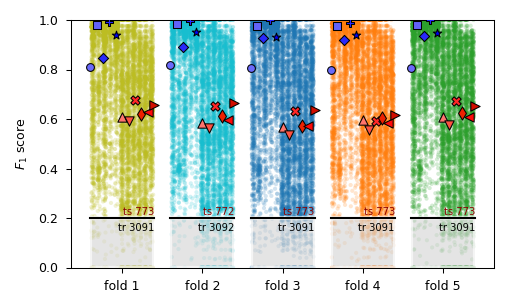

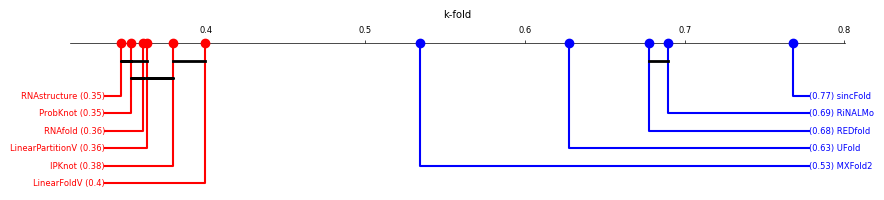

bpRNA


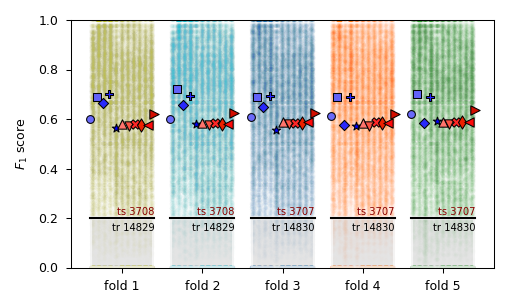

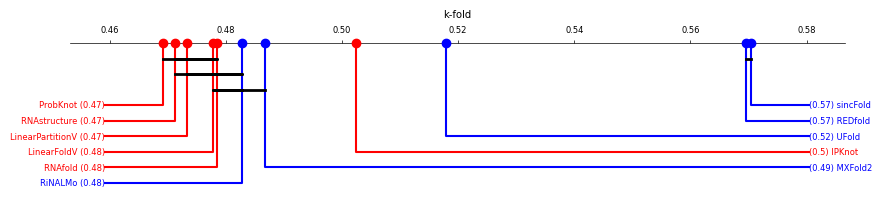

In [23]:
partition_name = "random_kfolds"
strip_alpha = {"archiveII": 0.2, "bpRNA": 0.01} # bpRNA has ~5x more test sequences per fold
for dataset in DATASETS:
    print(dataset)
    split = read_split(dataset, partition_name)
    summary = load_summary(dataset, partition_name)
    strip_folds(summary, split, strip_alpha=strip_alpha[dataset])
    save(dataset, partition_name)
    cdplot(summary, dataset, partition_name)

# Clustering folds

archiveII


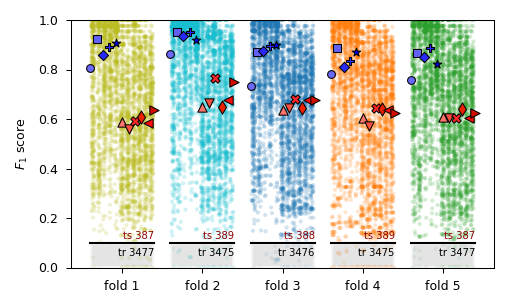

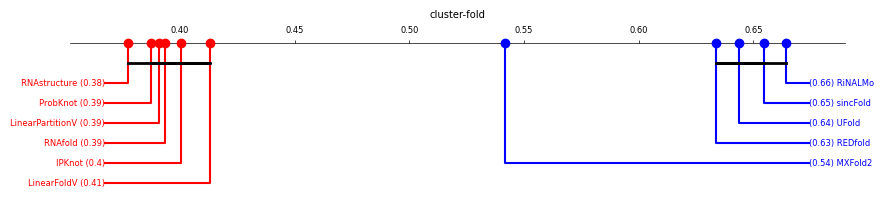

bpRNA


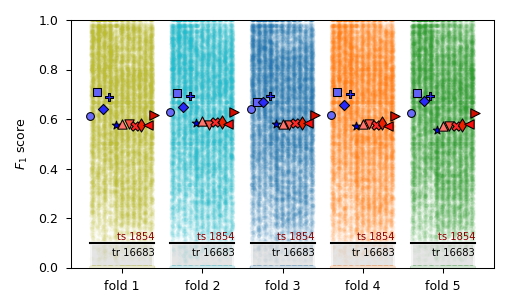

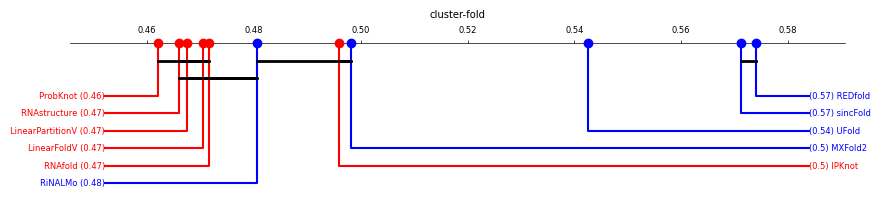

In [24]:
partition_name = "clustering_folds"
strip_alpha = {"archiveII": 0.2, "bpRNA": 0.05}
for dataset in DATASETS:
    print(dataset)
    split = read_split(dataset, partition_name)
    summary = load_summary(dataset, partition_name)
    strip_folds(summary, split, strip_alpha=strip_alpha[dataset])
    save(dataset, partition_name)
    cdplot(summary, dataset, partition_name)

# Family folds

ArchiveII: one family left out per fold. bpRNA: trained once on the bpRNA partition and
tested on the 20 largest families of bpRNA-new (one fold per family, largest first); the
bars show only the test size of each family, since all share the same training set.

archiveII


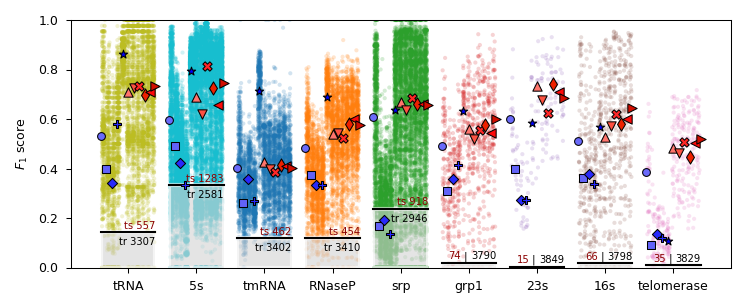

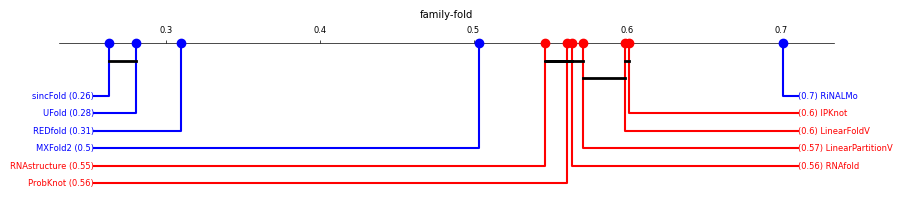

bpRNA


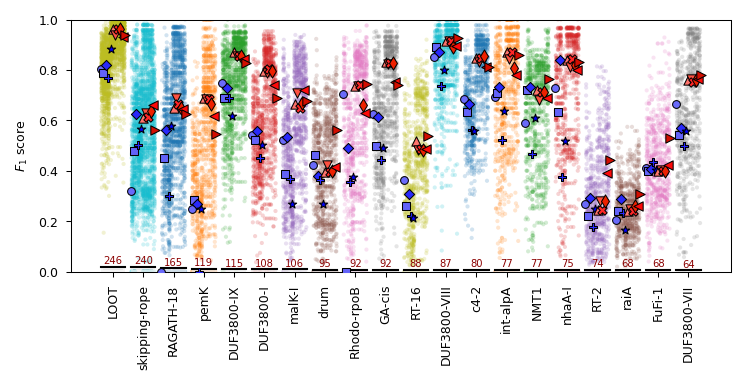

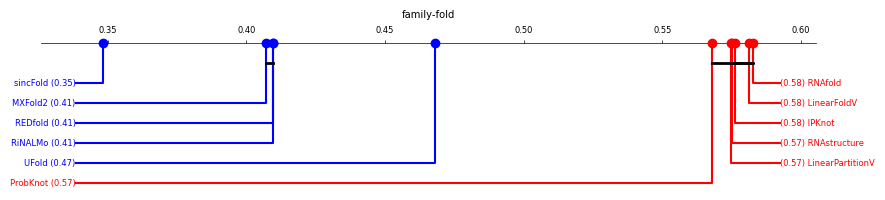

In [25]:
partition_name = "fam_folds"
for dataset in DATASETS:
    print(dataset)
    split = read_split(dataset, partition_name)
    summary = load_summary(dataset, partition_name)
    if dataset == "archiveII":
        sorted_families = ['tRNA', '5s', 'tmRNA', 'RNaseP', 'srp', 'grp1', '23s', '16s', 'telomerase'] # from RNA-LLM paper
        strip_folds(summary, split, x="family", order=sorted_families, fig_size="2x3in2col")
    else:
        sorted_families = list(split.sort_values("fold_number")["fold_name"].unique())
        train = pd.read_csv(f"{DATA_PATH}data/bpRNA/fam_folds_train_split.csv")
        strip_folds(summary, split, x="family", order=sorted_families, fig_size="2x3in2col", fig_height=2.51,
                    n_train=int((train["partition"] != "test").sum()), rotate_xticks=True)
    save(dataset, partition_name)
    cdplot(summary, dataset, partition_name)

# Human learned folds

archiveII


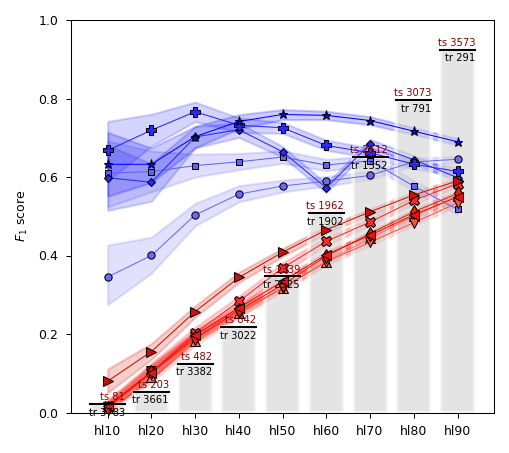

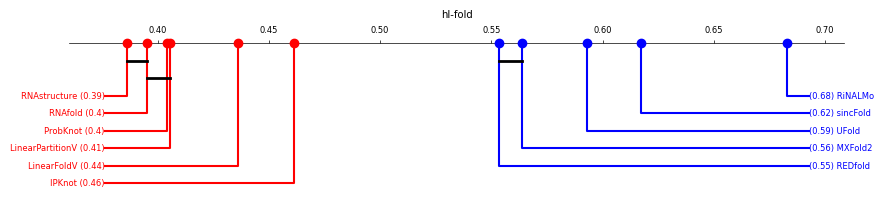

bpRNA


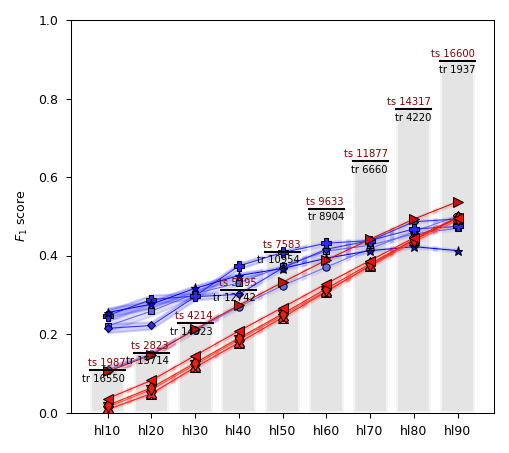

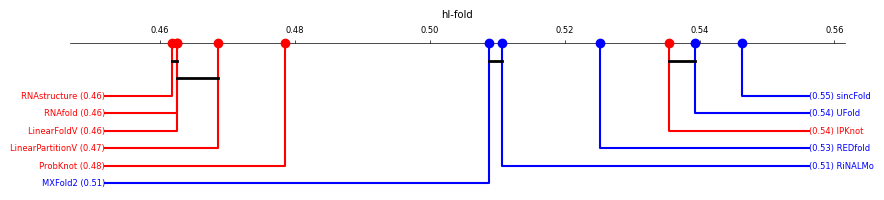

In [26]:
partition_name = "hl_folds"
for dataset in DATASETS:
    print(dataset)
    split = read_split(dataset, partition_name)
    summary = load_summary(dataset, partition_name)
    hl_order = sorted(summary["fold"].unique(), key=lambda f: int(f[2:]))
    line_folds(summary, split, x="fold", order=hl_order)
    save(dataset, partition_name)
    cdplot(summary, dataset, partition_name)

# Similarity folds

archiveII


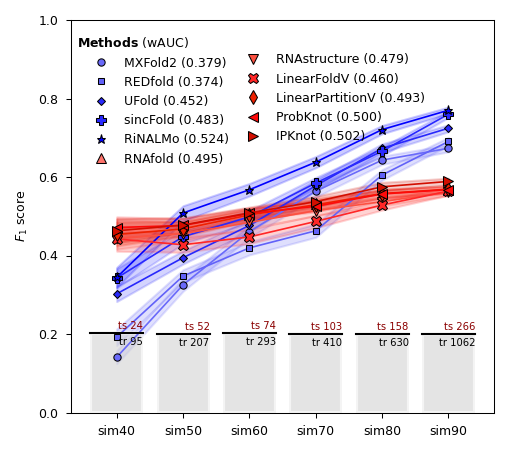

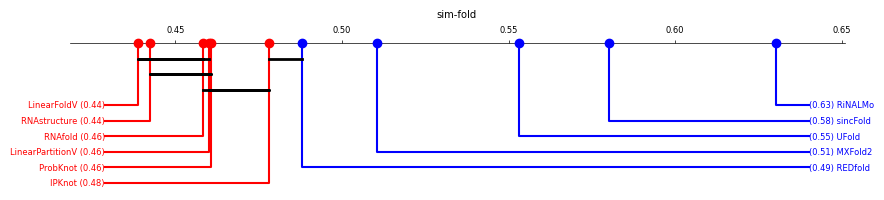

bpRNA


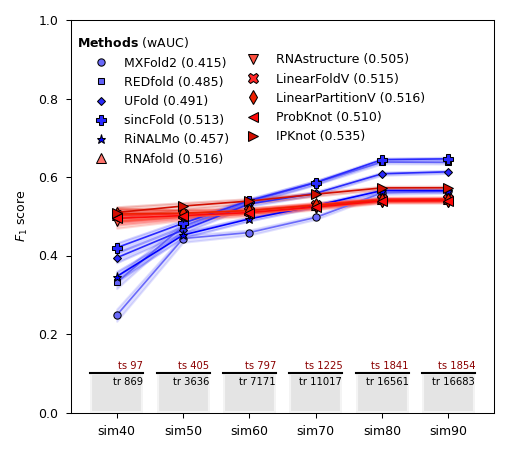

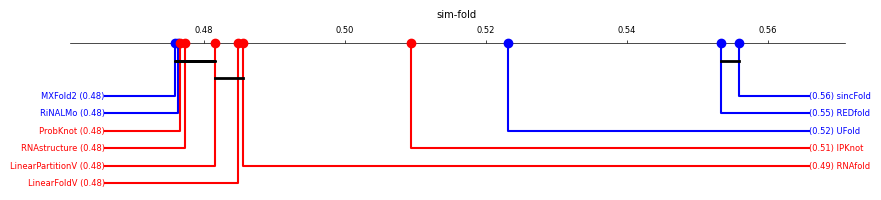

In [27]:
partition_name = "sim_folds"
for dataset in DATASETS:
    print(dataset)
    split = read_split(dataset, partition_name)
    summary = load_summary(dataset, partition_name)
    AUCsim = sim_auc(summary)
    sim_order = sorted(summary["similarity"].unique(), key=lambda s: int(s[3:]))
    fig, ax = line_folds(summary, split, x="similarity", order=sim_order, sizes_fold=0, train_dy=0.01, linewidth=0.8)

    # legend with the weighted area under the curve of each method, in two columns
    methods = [m for m in METHODS if m in set(summary["method"])]
    handles = [Line2D([0], [0], marker=STYLE[m]["marker"], color='w', markerfacecolor=STYLE[m]["color"],
                      markeredgecolor='black', markeredgewidth=0.5, markersize=STYLE[m]["size"], linestyle='')
               for m in methods]
    labels = [f"{LABELS.get(m, m)} ({AUCsim.loc[m, 'wAUC']:0.3f})" for m in methods]
    leg1 = fig.legend(handles[:6], labels[:6], title=r"$\mathbf{Methods}$ (wAUC)", loc='upper left',
                      bbox_to_anchor=(0.15, 0.95), fontsize=font_size, frameon=False, ncol=1)
    leg2 = fig.legend(handles[6:], labels[6:], loc='upper left',
                      bbox_to_anchor=(0.45, 0.91), fontsize=font_size, frameon=False, ncol=1)
    leg1.set_zorder(10)
    leg1.get_title().set_position((-25.5, 0))
    plt.tight_layout()
    save(dataset, partition_name)
    cdplot(summary, dataset, partition_name)

# Stratified random k-folds

archiveII


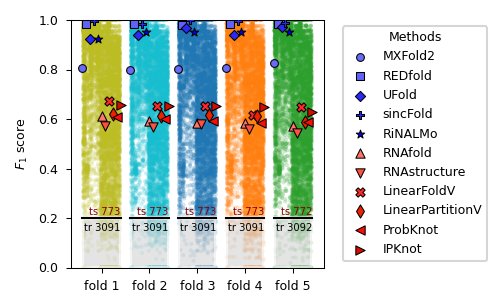

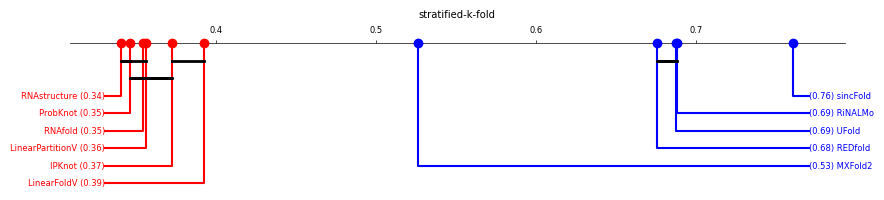

In [28]:
partition_name = "stratified_kfold"
for dataset in DATASETS:
    if not os.path.exists(f"{DATA_PATH}data/{dataset}/{partition_name}_split.csv"):
        continue
    print(dataset)
    split = read_split(dataset, partition_name)
    summary = load_summary(dataset, partition_name)
    strip_folds(summary, split, include_legend=True)
    save(dataset, partition_name)
    cdplot(summary, dataset, partition_name)